In [1]:
# Install the packages this notebook needs.
# If they are already installed, this step is quick and harmless.
%pip install -q pandas numpy matplotlib seaborn scipy

Note: you may need to restart the kernel to use updated packages.


# 06. The freedom versus outcomes gap, and what this project cannot prove

## Words first: the second original angle

A rank is a position in a list. The country with the highest
score is rank 1, the next is rank 2, and so on. This notebook
compares two ranks for the same country in 2016: its freedom
rank, and its GDP per capita rank. The gap is freedom rank minus
GDP rank.

If the gap is large and positive, the freedom rank number is
bigger, which means a lower freedom position, than the GDP
position. In plain words, the country ranks higher on GDP than
on freedom. If the gap is large and negative, it ranks higher on
freedom than on GDP.

A large gap is not good or bad. It is a prompt to look closer.
It may reflect natural resources, a small population, a
particular economic structure, or limits in either ranking.
This notebook reports the gaps and does not judge them.

In [2]:
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 150
plt.rcParams['figure.figsize'] = (10, 6)
ROOT = pathlib.Path('..').resolve()
CHARTS = ROOT / 'charts'
CHARTS.mkdir(exist_ok=True)
DATA = ROOT / 'data' / 'processed'
print('Data folder:', DATA)
print('Charts folder:', CHARTS)

Data folder: /home/hatch/workspace/repo-builds/human-freedom-index/data/processed
Charts folder: /home/hatch/workspace/repo-builds/human-freedom-index/charts


In [3]:
gap = pd.read_csv(DATA / 'freedom_gap.csv')
corr = pd.read_csv(DATA / 'correlations.csv')
print('Countries with both freedom and GDP data in 2016:', len(gap))
print()
print('Full correlation table, 2016:')
print(corr.round(3).to_string(index=False))

Countries with both freedom and GDP data in 2016: 161

Full correlation table, 2016:
 year    score                   outcome  n_countries  pearson_r  spearman_r
 2016 hf_score        gdp_per_capita_usd          161      0.618       0.689
 2016 pf_score        gdp_per_capita_usd          161      0.559       0.620
 2016 ef_score        gdp_per_capita_usd          161      0.565       0.682
 2016 hf_score     life_expectancy_years          161      0.621       0.662
 2016 pf_score     life_expectancy_years          161      0.532       0.582
 2016 ef_score     life_expectancy_years          161      0.616       0.682
 2016 hf_score infant_mortality_per_1000          160     -0.579      -0.703
 2016 pf_score infant_mortality_per_1000          160     -0.496      -0.636
 2016 ef_score infant_mortality_per_1000          160     -0.576      -0.688


## Freedom rank versus GDP rank

Each dot is a country in 2016. The diagonal line is where the
two ranks are equal. Dots far from the line have the largest
gaps. The table after the chart names the extremes, in both
directions, so the chart is not left to guesswork.

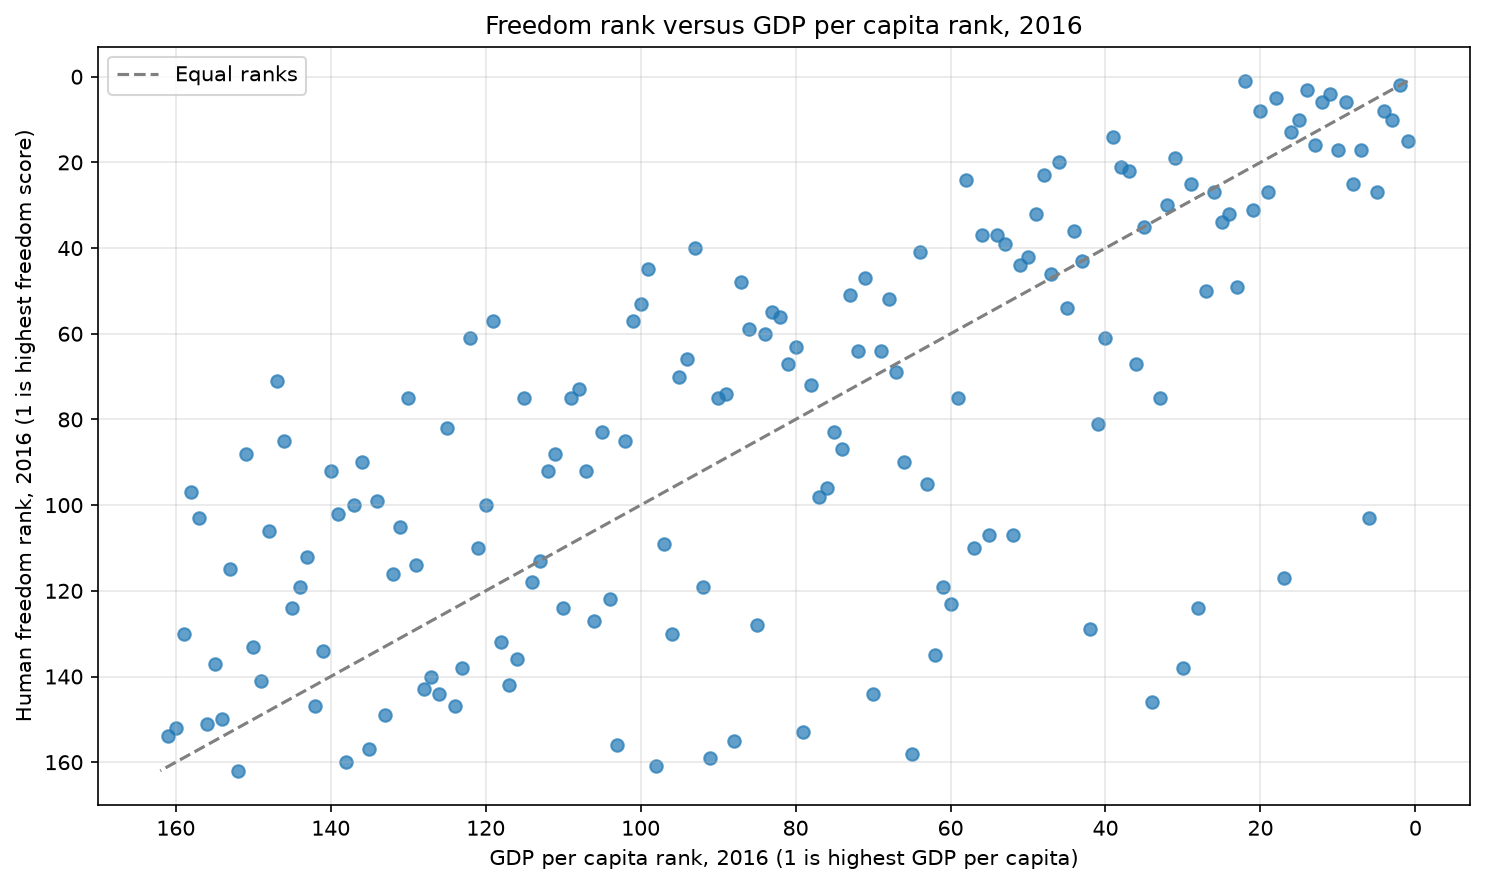

Largest gaps where GDP rank is higher than freedom rank:
             country  hf_rank  gdp_rank  freedom_minus_gdp_rank
               China    135.0      62.0                    73.0
                Iran    153.0      79.0                    74.0
               Gabon    144.0      70.0                    74.0
                Oman    129.0      42.0                    87.0
               Libya    158.0      65.0                    93.0
              Kuwait    124.0      28.0                    96.0
               Qatar    103.0       6.0                    97.0
United Arab Emirates    117.0      17.0                   100.0
   Brunei Darussalam    138.0      30.0                   108.0
        Saudi Arabia    146.0      34.0                   112.0

Largest gaps where freedom rank is higher than GDP rank:
     country  hf_rank  gdp_rank  freedom_minus_gdp_rank
      Rwanda     71.0     147.0                   -76.0
Burkina Faso     88.0     151.0                   -63.0
       Ghana 

In [4]:
fig, ax = plt.subplots()
ax.scatter(gap['gdp_rank'], gap['hf_rank'], alpha=0.7)
lim = max(gap['gdp_rank'].max(), gap['hf_rank'].max())
ax.plot([1, lim], [1, lim], color='grey', linestyle='--', label='Equal ranks')
ax.set_xlabel('GDP per capita rank, 2016 (1 is highest GDP per capita)')
ax.set_ylabel('Human freedom rank, 2016 (1 is highest freedom score)')
ax.set_title('Freedom rank versus GDP per capita rank, 2016')
ax.invert_xaxis()
ax.invert_yaxis()
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(CHARTS / 'chart_gap_scatter.png')
plt.show()
print('Largest gaps where GDP rank is higher than freedom rank:')
print(gap.tail(10)[['country', 'hf_rank', 'gdp_rank',
                    'freedom_minus_gdp_rank']].round(1).to_string(index=False))
print()
print('Largest gaps where freedom rank is higher than GDP rank:')
print(gap.head(10)[['country', 'hf_rank', 'gdp_rank',
                    'freedom_minus_gdp_rank']].round(1).to_string(index=False))

## The same gaps, as bars

The chart below shows the ten largest gaps in each direction,
so the size of each gap can be compared at a glance. The numbers
are rank places, not score points. A gap of 50 rank places does
not mean a gap of 50 points on any score.

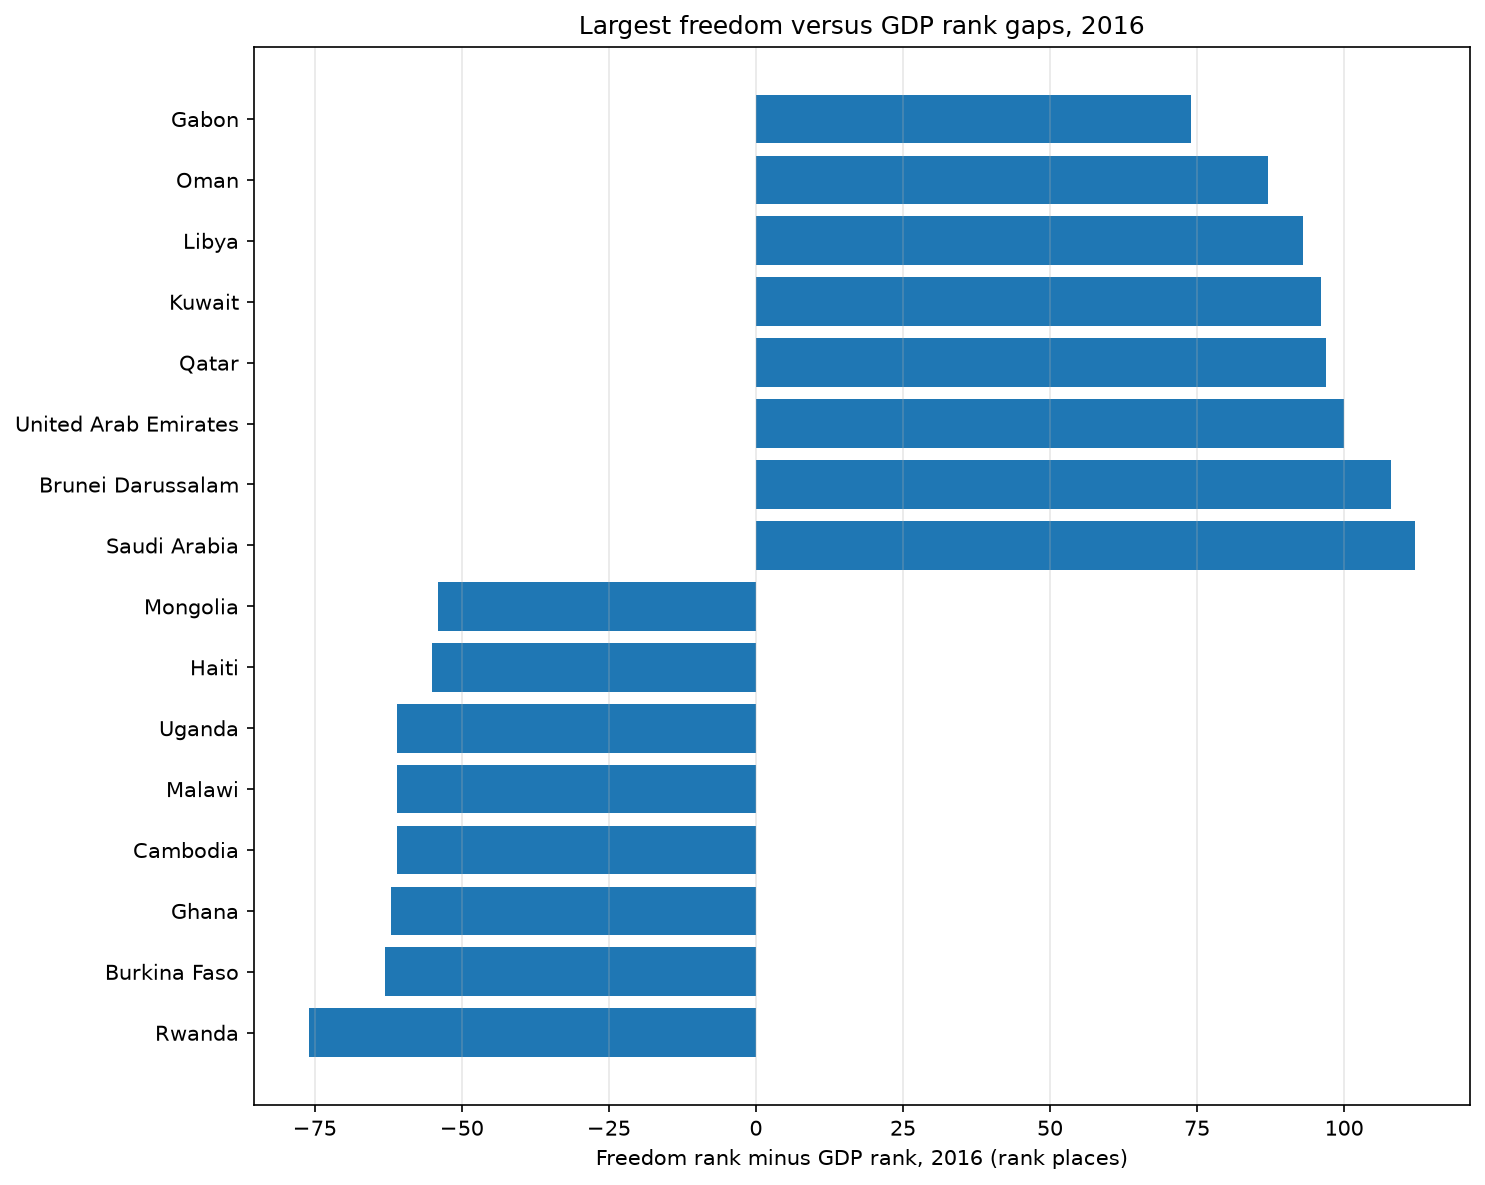

In [5]:
top_gap = gap.tail(8).iloc[::-1]
bot_gap = gap.head(8)
fig, ax = plt.subplots(figsize=(10, 8))
labels = list(bot_gap['country']) + list(top_gap['country'])
values = list(bot_gap['freedom_minus_gdp_rank']) + list(top_gap['freedom_minus_gdp_rank'])
ax.barh(labels, values)
ax.set_xlabel('Freedom rank minus GDP rank, 2016 (rank places)')
ax.set_title('Largest freedom versus GDP rank gaps, 2016')
ax.grid(axis='x', alpha=0.3)
fig.tight_layout()
fig.savefig(CHARTS / 'chart_gap_bars.png')
plt.show()

## Correlation versus causation, one more time

This project found, in 2016, that higher freedom scores go
together with higher GDP per capita, longer life expectancy,
and lower infant mortality. Those are correlations.

Causation would need much more: a reason to rule out other
explanations, a check over time, and a way to test what happens
when one thing changes and others do not. None of that is done
here, and none of it is claimed.

Also, this project uses one edition of one index, and one
outcome source, the World Bank. Other freedom measures exist,
and other researchers may weigh personal and economic freedom
differently. A different measure could give a different picture.
That does not make this picture wrong, but it does mean it is
one picture, not the only picture.

## Final takeaway

Freedom, as this index defines it, varies a lot across countries,
moves slowly for most countries over eight years, and lines up
with better average economic and health outcomes in 2016 without
proving that it causes them. The most useful habit this project
can leave is to ask, for any ranking: who made it, what went
into it, what year is it, and what is it not showing.